# Uso docente · Preparar los datos de la Unidad 2

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/crispaliz/modelacion-sismica-tsunami-espam/blob/main/cuadernos/DOCENTE_preparar_datos_U2.ipynb)

**Modelación Sísmica y Tsunami (IRD-505) · ESPAM MFL** · Docente: Cristian Paliz Acosta, MSc.

Este cuaderno descarga, para cada uno de los **11 eventos de la práctica 1** (incluido Pedernales 2016), todo lo que necesita el cuaderno del Capítulo 2 y lo que se usará después para la propagación (Unidad 3) y la inundación (Unidad 4). Lo deja en `datos/eventos/<evento>/` para subirlo al repositorio, de modo que los estudiantes trabajen **sin depender de que los servicios externos respondan** en el día de la clase (temporada de lluvias, cortes de internet).

| Archivo | Fuente | Qué contiene | Uso |
|---|---|---|---|
| `evento.json` | USGS ComCat (servicio FDSN) | Origen, magnitud, tensor de momento W-phase, planos nodales, enlaces a los productos | Paso 0 y rectángulo uniforme |
| `falla_finita.param` / `.fsp` | USGS, producto *finite-fault* | Subfallas con deslizamiento, rake, rumbo, buzamiento y tiempos de ruptura | Pasos 2 a 5 |
| `batimetria_regional.nc` | NOAA ETOPO 2022 (ERDDAP), 1′ (≈1,8 km) | Elevación y batimetría de la región del evento | Mallas de la U2 y propagación (U3) |
| `batimetria_costa_<localidad>.nc` | ETOPO 2022, 15″ (≈450 m), ±0,3° | Elevación y batimetría alrededor de cada localidad | Base para la inundación indicativa (U4) |
| `slab2_profundidad.grd` | USGS Slab2 (ScienceBase) | Profundidad del techo de la placa subducida | Paso 1 (opcional) |
| `observaciones.csv` | — | Plantilla vacía | La completan los grupos (Paso 6) |

**Se ejecuta una sola vez**, en Colab, y tarda unos 10 a 20 minutos para los 11 eventos.

**Qué esperar por evento**
- Los eventos recientes (Pedernales, Maule, Illapel, Iquique, Tohoku, Océano Índico) suelen tener falla finita del USGS.
- Los más antiguos (Nicaragua 1992, Camaná 2001, Pisco 2007) pueden no tenerla. En ese caso el cuaderno de estudiantes usa el rectángulo del tensor de momento, subdividido para la cinemática; queda indicado en el informe del final.
- Slab2 se intenta bajar automáticamente desde ScienceBase. Si falla, el cuaderno de estudiantes usa la geometría de la falla finita. Para agregarlo a mano: https://doi.org/10.5066/F7PV6JNV, archivo `<región>_slab2_dep_*.grd` (`sam` Sudamérica, `kur` Japón-Kuriles, `sum` Sumatra, `cam` Centroamérica), guardado como `slab2_profundidad.grd` en la carpeta del evento.

In [1]:
import os, sys, json
CARPETA = "/content/modelacion-sismica-tsunami-espam"
if not os.path.exists(CARPETA):
    !git clone -q https://github.com/crispaliz/modelacion-sismica-tsunami-espam {CARPETA}
sys.path.insert(0, os.path.join(CARPETA, "src"))
import deformacion as dfm
from deformacion import datos
RAIZ = os.path.join(CARPETA, "datos", "eventos")
print("Eventos:", list(dfm.EVENTOS))

Eventos: ['Pedernales 2016', 'Maule 2010', 'Illapel 2015', 'Iquique 2014', 'Pisco 2007', 'Camaná 2001', 'Tohoku 2011', 'Nicaragua 1992', 'Mentawai 2010', 'Samoa 2009', 'Océano Índico 2012']


## Descargar
Para cada evento: se busca en el USGS por fecha, zona y magnitud; se leen el tensor y los enlaces de la falla finita; se descargan la falla finita, la batimetría regional, la costera de cada localidad y, si se puede, Slab2.

Si un evento falla (servicio caído, sin tensor), se informa y se sigue con el siguiente. Para repetir solo los que fallaron, pongan sus nombres en `EVENTOS_A_DESCARGAR`. La tabla final resume qué se obtuvo de cada evento.

In [2]:
EVENTOS_A_DESCARGAR = list(dfm.EVENTOS)      # o una lista parcial, p. ej. ["Maule 2010"]
INFORME = {}
for nombre in EVENTOS_A_DESCARGAR:
    try:
        m = datos.preparar_evento(nombre, RAIZ, slab=True, costa=True)
        INFORME[nombre] = dict(id_usgs=m["id_usgs"], Mw=m["magnitud"],
                               tensor=bool(m.get("tensor")), falla_finita=m.get("archivo_falla_finita"),
                               slab2=m.get("archivo_slab2"), costas=len(m.get("batimetria_costa", {})))
    except Exception as e:
        INFORME[nombre] = dict(error=str(e)[:200])
        print("   ✗", nombre, e)
import pandas as pd
pd.DataFrame(INFORME).T

■ Pedernales 2016
   USGS us20005j32 · M7.8 · falla finita: sí
   batimetría regional (1′) lista
   batimetría costera (15″) lista
   Slab2: sí
■ Maule 2010
   USGS official20100227063411530_30 · M8.8 · falla finita: sí
   batimetría regional (1′) lista
   batimetría costera (15″) lista
   Slab2: sí
■ Illapel 2015
   USGS us20003k7a · M8.3 · falla finita: sí
   batimetría regional (1′) lista
   batimetría costera (15″) lista
   Slab2: sí
■ Iquique 2014
   USGS usc000nzvd · M8.2 · falla finita: sí
   batimetría regional (1′) lista
   batimetría costera (15″) lista
   Slab2: sí
■ Pisco 2007
   USGS usp000fjta · M8 · falla finita: sí
   batimetría regional (1′) lista
   batimetría costera (15″) lista
   Slab2: sí
■ Camaná 2001
   USGS official20010623203314130_33 · M8.4 · falla finita: sí
   batimetría regional (1′) lista
   batimetría costera (15″) lista
   Slab2: sí
■ Tohoku 2011
   USGS official20110311054624120_30 · M9.1 · falla finita: sí
   batimetría regional (1′) lista
   batimetr

,id_usgs,Mw,tensor,falla_finita,slab2,costas
Pedernales 2016,us20005j32,7.8,True,falla_finita.param,slab2_profundidad.grd,1
Maule 2010,official20100227063411530_30,8.8,True,falla_finita.param,slab2_profundidad.grd,3
Illapel 2015,us20003k7a,8.3,True,falla_finita.param,slab2_profundidad.grd,3
Iquique 2014,usc000nzvd,8.2,True,falla_finita.param,slab2_profundidad.grd,2
Pisco 2007,usp000fjta,8,True,falla_finita.param,slab2_profundidad.grd,3
Camaná 2001,official20010623203314130_33,8.4,True,falla_finita.param,slab2_profundidad.grd,3
Tohoku 2011,official20110311054624120_30,9.1,True,falla_finita.param,slab2_profundidad.grd,4
Nicaragua 1992,usp0005ddn,7.7,True,falla_finita.param,slab2_profundidad.grd,3
Mentawai 2010,usp000hnj4,7.8,True,falla_finita.param,slab2_profundidad.grd,2
Samoa 2009,usp000h1ys,8.1,True,falla_finita.param,None,3


## Control visual
Un mapa por evento con la falla finita (o el rectángulo del tensor, si no hay) sobre la batimetría. El título indica cuál se dibujó.

**Qué revisar en cada mapa**
- La falla queda frente a la costa correcta y la estrella (epicentro) cae dentro o en el borde de la ruptura.
- En las subducciones, la falla buza hacia el continente: el borde somero queda del lado de la fosa.
- Los círculos rojos (localidades) quedan frente a la ruptura y dentro de la región de batimetría.
- Samoa 2009 (normal, fuera de la fosa) y Océano Índico 2012 (rumbo) no siguen el patrón de subducción: es lo esperado.

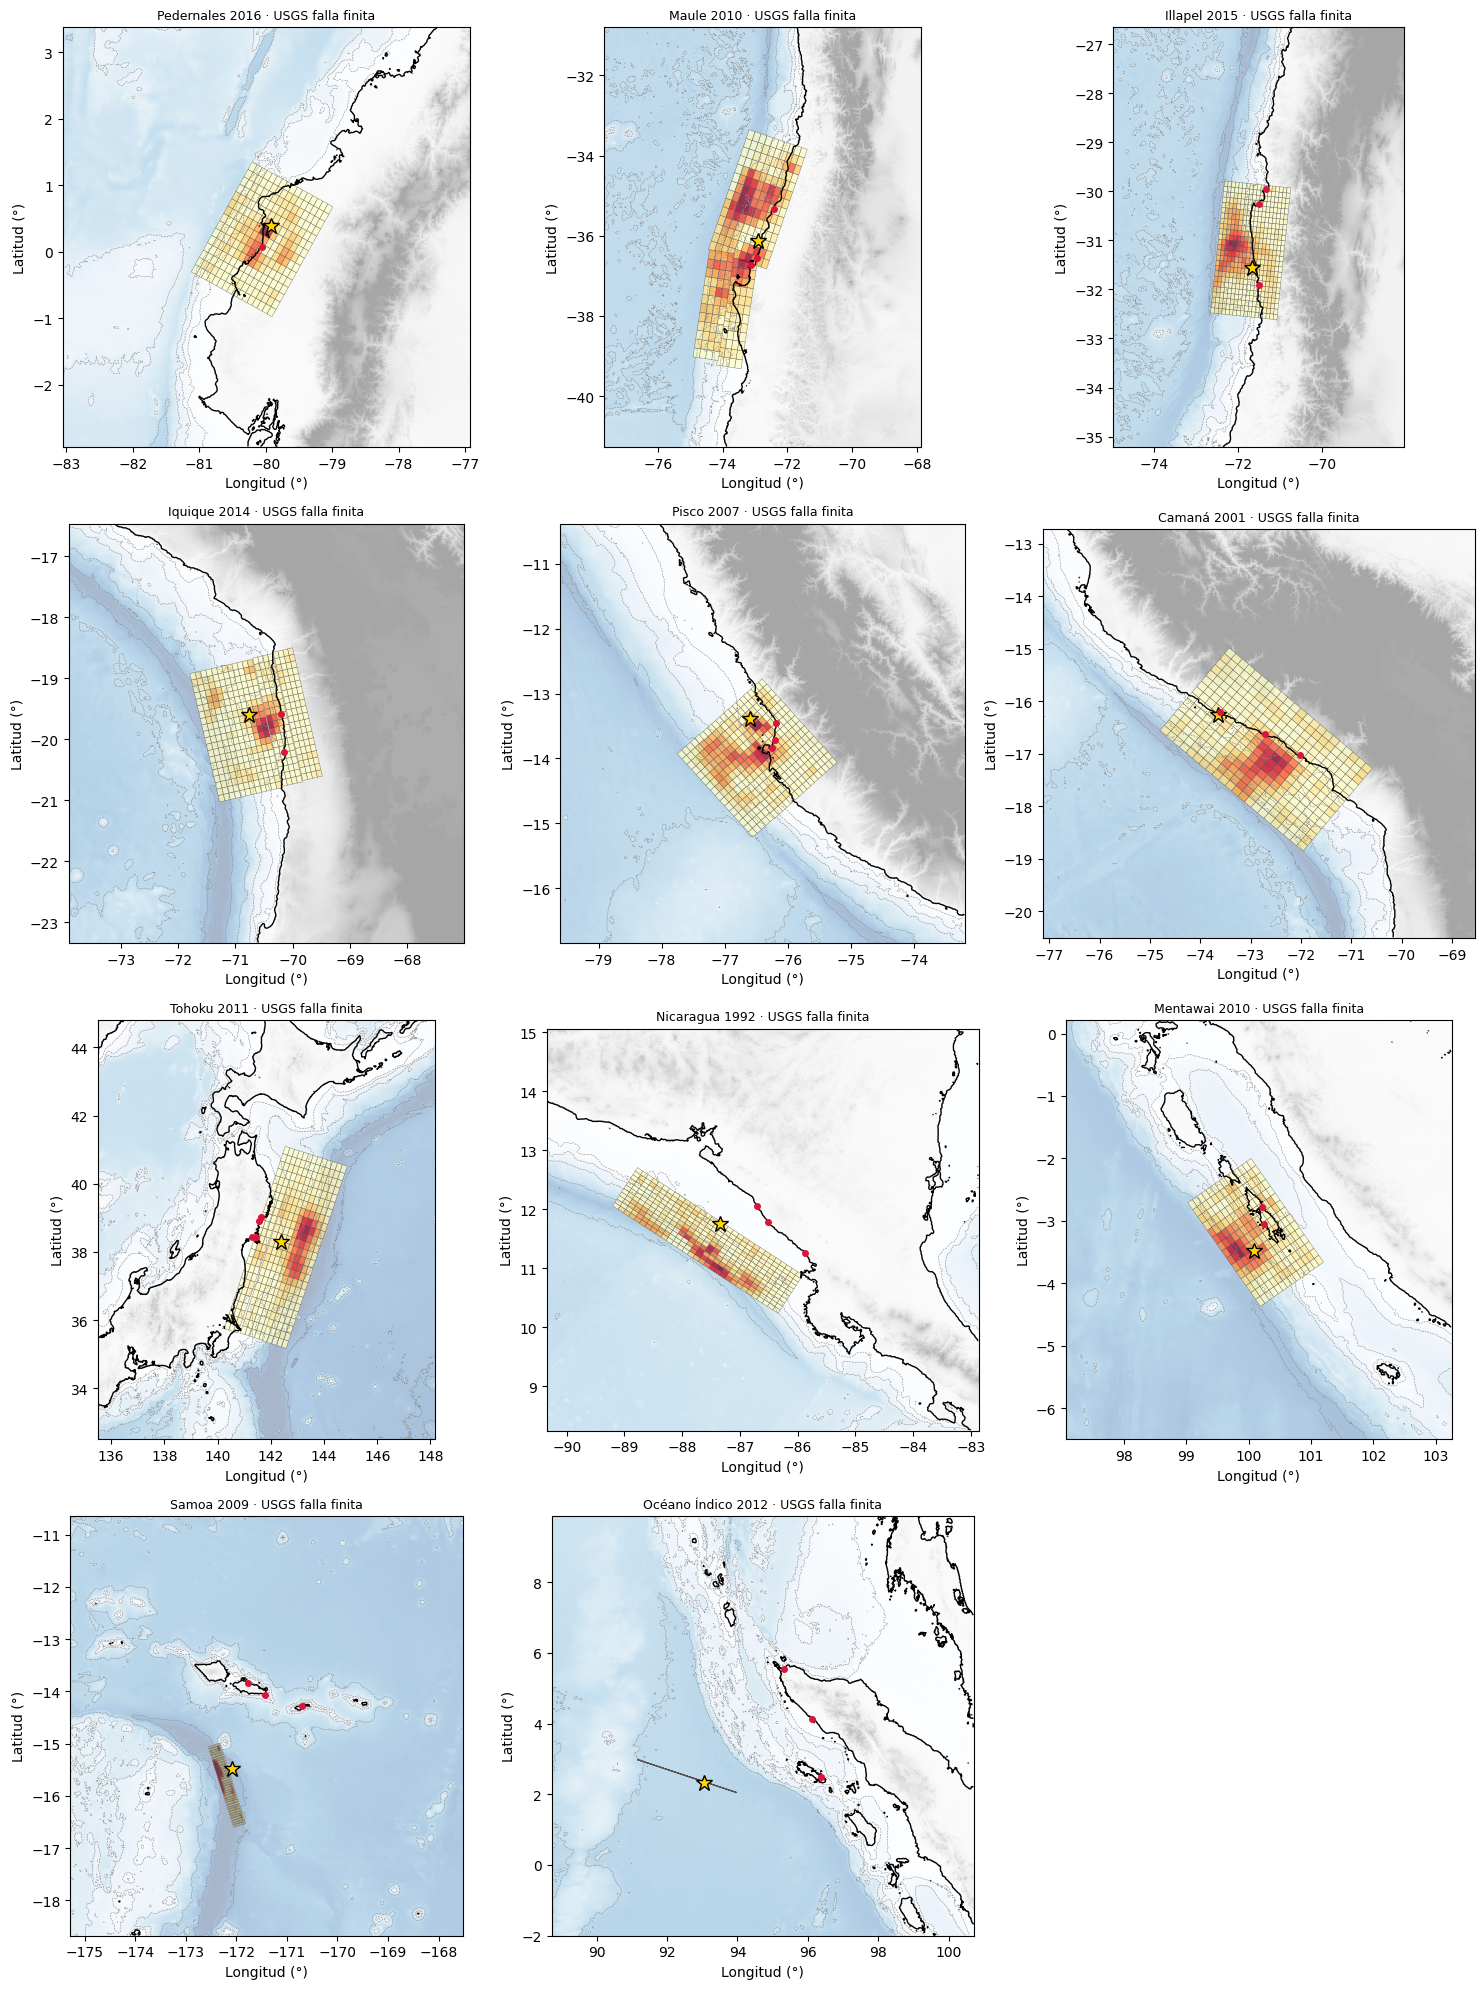

In [3]:
import numpy as np, matplotlib.pyplot as plt
from deformacion import graficos as gr
nombres = [n for n in EVENTOS_A_DESCARGAR if "error" not in INFORME.get(n, {"error": 1})]
cols = 3; filas = int(np.ceil(len(nombres) / cols))
fig, axs = plt.subplots(filas, cols, figsize=(5 * cols, 5 * filas), squeeze=False)
for a, nombre in zip(axs.ravel(), nombres):
    D = datos.cargar_evento(nombre, RAIZ)
    lo, la, z = D["batimetria"]
    gr.mapa_base(a, lo, la, z)
    F = D["falla_finita"] or dfm.falla_desde_tensor(nombre, D["meta"])
    gr.dibujar_falla(a, F)
    h = D["meta"]["hipocentro"]; a.plot(h["lon"], h["lat"], "*", color="gold", ms=12, mec="k")
    for loc, (lat_l, lon_l) in dfm.LOCALIDADES[nombre].items():
        a.plot(lon_l, lat_l, "o", color="crimson", ms=4)
    a.set_title(f"{nombre} · {F.origen.split(' ·')[0]}", fontsize=9)
for a in axs.ravel()[len(nombres):]: a.axis("off")
plt.tight_layout(); plt.show()

## Resumen y paquete
Se guarda `datos/eventos/indice_eventos.json` con el estado de cada evento y se genera un `.zip` de la carpeta `datos/eventos/` para subirlo al repositorio.

**Subir a GitHub** (dos opciones):
1. Descargar el `.zip`, descomprimirlo en la copia local del repositorio y hacer *commit* y *push*.
2. Desde Colab, con un token personal de GitHub (permiso `contents: write`) guardado en los *Secretos* de Colab como `GITHUB_TOKEN`, ejecutar la última celda.

In [4]:
with open(os.path.join(RAIZ, "indice_eventos.json"), "w", encoding="utf-8") as fh:
    json.dump(INFORME, fh, ensure_ascii=False, indent=2, default=str)
import shutil
ZIP = shutil.make_archive("/content/datos_IRD505", "zip", RAIZ)
print("Tamaño:", round(os.path.getsize(ZIP) / 1e6, 1), "MB")
try:
    from google.colab import files; files.download(ZIP)
except ImportError:
    print(ZIP)

Tamaño: 14.3 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [5]:
# Opcional: subir directamente al repositorio (requiere el secreto GITHUB_TOKEN en Colab)
SUBIR = False
if SUBIR:
    from google.colab import userdata
    tok = userdata.get("GITHUB_TOKEN")
    %cd {CARPETA}
    !git config user.email "cristian.paliz@espam.edu.ec" && git config user.name "Cristian Paliz"
    !git add datos/eventos && git commit -m "Datos de los eventos para la Unidad 2" && \
     git push https://{tok}@github.com/crispaliz/modelacion-sismica-tsunami-espam.git HEAD:main